# Calcul-01 — Équation différentielle linéaire : forme close, erreur mesurée, preuve formelle

**Navigation** : [Index de la série](README.md) | [Parcours de notebooks](../README.md)

## Objectifs pédagogiques

1. Poser une équation différentielle linéaire à coefficient variable et en obtenir la forme close avec SymPy.
2. Contrôler cette forme close **par substitution** — résidu nul sur l'équation et sur la condition initiale — et vérifier que le contrôle sait refuser un candidat faux.
3. Résoudre la même équation avec SciPy et **mesurer** l'écart à la forme close sur plusieurs tolérances, en reconnaissant le réglage grossier qui ne suffit pas.
4. Distinguer ce qu'un pas de temps garantit (stabilité) de ce qu'il ne garantit pas (précision).
5. Lire un énoncé Lean qui répond à la même question et nommer ce qu'il certifie — ce qu'une mesure numérique ne certifie pas.

## Prérequis

Équations différentielles du premier ordre, exponentielle et sinus ; Python de base (fonctions, boucles, tableaux `numpy`).

## Durée estimée : 45-60 minutes

Ce carnet ouvre la série *Calcul scientifique*. Il est volontairement CPU : aucun matériel dédié, aucune stochasticité — chaque exécution rejoue les mêmes nombres.


### Environnement opérationnel

Le carnet n'utilise que `numpy`, `scipy`, `sympy` et `matplotlib`. La cellule suivante imprime les versions effectives : une erreur mesurée n'a de sens que rattachée aux bibliothèques qui l'ont produite.


In [1]:
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import scipy
import sympy as sp
from scipy.integrate import solve_ivp

# Les versions sont imprimees avant tout calcul : une erreur mesuree plus bas
# ne vaut que pour ces bibliotheques-la.
print("python     :", sys.version.split()[0])
print("sympy      :", sp.__version__)
print("scipy      :", scipy.__version__)
print("numpy      :", np.__version__)
print("matplotlib :", matplotlib.__version__)
print("Imports réussis : les quatre bibliothèques sont présentes "
      "(disponibilité seule, ce n'est pas un test de bon fonctionnement).")


python     : 3.13.16
sympy      : 1.14.0
scipy      : 1.18.1
numpy      : 2.5.2
matplotlib : 3.10.3
Imports réussis : les quatre bibliothèques sont présentes (disponibilité seule, ce n'est pas un test de bon fonctionnement).


**Lecture.** Les versions ci-dessus nomment les bibliothèques qui produiront tout le reste : SymPy calcule exactement, SciPy intègre numériquement, Matplotlib trace, NumPy porte les tableaux. Elles sont imprimées avant le premier calcul parce que les valeurs d'erreur des parties suivantes en dépendent — republier le même carnet avec une autre version de SciPy peut déplacer les chiffres à la dernière décimale, même si aucune ligne de code n'a changé.


## Partie 1 — Une équation, une forme close, un résidu

### 1.1 Le problème

Une grandeur $C(t)$ décroît à un rythme qui dépend du temps :

$$\frac{\mathrm{d}C}{\mathrm{d}t} = -\kappa(t)\,C(t), \qquad \kappa(t) = k_0\bigl(1 + \varepsilon\cos(\omega t)\bigr), \qquad C(0) = C_0.$$

Lecture physique : $C$ est l'écart de température d'un corps à celle de son milieu — le refroidissement de Newton — et $\kappa$ un coefficient d'échange modulé périodiquement, par le cycle jour-nuit par exemple. Les paramètres sont supposés strictement positifs, avec $0 < \varepsilon < 1$ pour que $\kappa$ le reste : la grandeur se refroidit toujours, jamais ne se réchauffe.

Le problème tient en une ligne, et il admet une forme close. C'est ce qui en fait un bon étalon : aucune discrétisation n'est nécessaire pour savoir à quoi la réponse exacte ressemble. On peut y poser trois questions d'égale importance, et ce carnet les prend dans l'ordre.

1. **Quelle est la solution exacte ?** Un calcul formel peut la produire, et un contrôle peut vérifier qu'elle satisfait l'équation.
2. **Que vaut-elle à une tolérance donnée ?** Un solveur peut l'approcher ; l'écart à la forme close se mesure alors, et c'est ce chiffre — pas le solveur — qui dit la qualité du résultat.
3. **Que peut-on affirmer sans calculer aucune valeur ?** Par exemple : si $C_0 = 0$, la solution reste-t-elle nulle pour tout $t$ ? Un énoncé formel peut certifier une telle conséquence.


### 1.2 Laisser SymPy résoudre

SymPy ne devine pas la solution : il classe l'équation, applique l'algorithme adapté à cette classe, puis utilise la condition initiale pour fixer la constante. On lui donne l'équation et la condition ensemble ; ce qu'il rend est une expression symbolique, où $k_0$, $\varepsilon$, $\omega$ et $C_0$ restent des lettres.

Garder les paramètres symboliques n'est pas un luxe : c'est ce qui permettra, à la section 1.3, de vérifier l'égalité **pour toutes les valeurs** au lieu de la tester sur un jeu de nombres.


In [2]:
# Les parametres restent symboliques : la forme close vaudra pour toute valeur positive.
t = sp.symbols("t", real=True)
k0, eps, omega, C0 = sp.symbols("k0 epsilon omega C0", positive=True)


def kappa(k0v, epsv, omegav):
    """Coefficient de perte module : k0 * (1 + eps * cos(omega * t))."""
    return k0v * (1 + epsv * sp.cos(omegav * t))


# L'equation C'(t) = -kappa(t) * C(t), assortie de la condition initiale C(0) = C0.
C = sp.Function("C")
equation = sp.Eq(C(t).diff(t), -kappa(k0, eps, omega) * C(t))
solution = sp.dsolve(equation, C(t), ics={C(0): C0})

print("Équation posée     :", equation)
print("Condition initiale : C(0) =", C0)
print("Forme close        :", solution.rhs)


Équation posée     : Eq(Derivative(C(t), t), -k0*(epsilon*cos(omega*t) + 1)*C(t))
Condition initiale : C(0) = C0
Forme close        : C0*exp(k0*(-epsilon*sin(omega*t)/omega - t))


**Lecture.** SymPy a rendu une forme close : la solution est le produit de l'exponentielle d'une **décroissance régulière** en $-k_0 t$ par celle d'une **correction périodique** portée par $\sin(\omega t)$. Trois faits se lisent dans l'expression.

- La correction est bornée : son amplitude dans l'exposant vaut $\frac{k_0\varepsilon}{\omega}$. Elle ne change donc pas le taux de décroissance moyen, seulement le détail du trajet.
- Quand $\varepsilon$ tend vers zéro, le second terme s'efface et l'on retrouve $C_0\,e^{-k_0 t}$ : le refroidissement de Newton non modulé.
- La dérivée de $\sin(\omega t)$ redonne le $\cos(\omega t)$ présent dans $\kappa$ : c'est la trace de l'intégration qui a « défait » le coefficient de perte.

Le troisième point est une intuition, pas une vérification. La section suivante en fait un contrôle.


### 1.3 Contrôler par substitution

Obtenir une expression n'est pas la vérifier. Le contrôle le plus direct ne demande aucune confiance dans l'algorithme de résolution : on **remplace** la candidate dans l'équation, on simplifie l'expression obtenue, et elle doit s'annuler. Identiquement — pas « à peu près », et pas seulement pour un jeu de valeurs. Le même geste s'applique à la condition initiale.

Un contrôle n'a de valeur que s'il sait aussi **refuser**. On lui soumet donc un candidat faux mais plausible : la solution non modulée $C_0\,e^{-k_0 t}$, celle qu'on écrirait en oubliant que $\kappa$ varie. Si le contrôle acceptait les deux, il n'aurait rien départagé.


In [3]:
# Controle 1 : la candidate remplacee dans C'(t) + kappa(t) * C(t) doit donner zero.
residu = sp.simplify(sp.diff(solution.rhs, t) + kappa(k0, eps, omega) * solution.rhs)

# Controle 2 : la meme candidate doit valoir C0 en t = 0.
residu_ci = sp.simplify(solution.rhs.subs(t, 0) - C0)

# Temoin negatif : la solution non modulee, ecrite en oubliant les variations de kappa.
candidat_faux = C0 * sp.exp(-k0 * t)
residu_faux = sp.simplify(sp.diff(candidat_faux, t) + kappa(k0, eps, omega) * candidat_faux)

print("Résidu de la forme close sur l'équation :", residu)
print("Résidu sur la condition initiale        :", residu_ci)
print("Résidu du candidat faux sur l'équation  :", residu_faux)

# Une valeur suffit a voir que ce dernier residu n'est pas identiquement nul.
point = {t: 1, k0: 1, eps: sp.Rational(1, 2), omega: 3, C0: 1}
print("Candidat faux, au point t = 1           :", residu_faux.subs(point))
print("  soit, en décimal                      :", float(residu_faux.subs(point)))


Résidu de la forme close sur l'équation : 0
Résidu sur la condition initiale        : 0
Résidu du candidat faux sur l'équation  : C0*epsilon*k0*exp(-k0*t)*cos(omega*t)
Candidat faux, au point t = 1           : exp(-1)*cos(3)/2
  soit, en décimal                      : -0.18209894320664644


**Lecture.** La sortie donne deux zéros exacts et un résidu non nul, et c'est la comparaison qui compte.

- **La forme close passe les deux contrôles** : le résidu sur l'équation et celui sur la condition initiale valent zéro, symboliquement. L'égalité vaut donc pour tous les paramètres, pas seulement pour ceux qu'on essaiera plus bas.
- **Le candidat faux échoue**, et son résidu a une forme lisible : $C_0\,\varepsilon k_0\,e^{-k_0 t}\cos(\omega t)$. C'est exactement le terme de modulation que le candidat avait oublié. Au point choisi, il vaut une quantité non nulle, négative parce que $\cos(3)$ l'est.

Sans la seconde ligne, la première serait creuse : rien ne garantirait que le contrôle sache distinguer une solution d'une expression plausible. Avec elle, on sait que le zéro de la première ligne est une décision, pas une complaisance de `simplify`. Ce que ce contrôle **ne** dit pas encore : si d'autres solutions existent. On y revient en partie 3.


### 1.4 Ce que le calcul exact a établi — et ce qu'il n'a pas établi

« SymPy a résolu l'équation » peut recouvrir trois choses différentes. Il vaut la peine de les séparer avant d'aller plus loin.

| Question | Réponse | Établi par |
|---|---|---|
| L'expression rendue satisfait-elle l'équation et la condition initiale ? | Oui, identiquement. | Les deux résidus nuls de la section 1.3. |
| Existe-t-il une **autre** solution avec la même condition initiale ? | SymPy n'en a produit qu'une ; il n'a rien démontré à ce sujet. | Rien, pour l'instant. |
| Que vaut la solution à un instant donné, pour des paramètres donnés ? | Rien encore : tout reste symbolique. | La partie 2. |

Le calcul exact a donc établi une chose — *cette expression est une solution* — et non son unicité. C'est une question de nature différente, qu'un résidu ne tranche pas et qu'aucun solveur numérique ne tranchera : un solveur calcule **une** trajectoire, il ne dit pas si c'est la seule.


### 1.5 Choisir des valeurs, rendre la forme close calculable

Pour mesurer quoi que ce soit, il faut des nombres. Le **cas de base** de ce carnet est $k_0 = 1$, $\varepsilon = 0{,}5$, $\omega = 3$ et $C_0 = 1$, observé sur $0 \le t \le 10$.

La forme close symbolique devient une fonction numérique par `lambdify`. Elle jouera le rôle de **référence** dans toute la partie 2 : toute erreur y sera mesurée contre elle, jamais contre une autre sortie du solveur.


In [4]:
# Cas de base : les valeurs sont fixees une fois pour tout le carnet.
CAS_BASE = {"k0": 1.0, "eps": 0.5, "omega": 3.0, "C0": 1.0}
T_FIN = 10.0

# La forme close symbolique devient une fonction numerique : c'est la reference.
reference_sym = sp.lambdify((t, k0, eps, omega, C0), solution.rhs, "numpy")


def reference(instants, cas):
    """Forme close evaluee sur un tableau d'instants, pour un jeu de parametres."""
    return reference_sym(instants, cas["k0"], cas["eps"], cas["omega"], cas["C0"])


# Les deux termes de l'exposant, sur le cas de base.
amplitude = CAS_BASE["k0"] * CAS_BASE["eps"] / CAS_BASE["omega"]
print("Amplitude de la correction périodique, k0 * eps / omega :", amplitude)
print("Décroissance régulière sur l'intervalle, k0 * T_FIN     :", CAS_BASE["k0"] * T_FIN)
print("Coefficient de perte : min =", CAS_BASE["k0"] * (1 - CAS_BASE["eps"]),
      "; max =", CAS_BASE["k0"] * (1 + CAS_BASE["eps"]))

# Deux valeurs de la reference, pour fixer les ordres de grandeur.
for instant in (1.0, 10.0):
    valeur = reference(np.array([instant]), CAS_BASE)[0]
    print(f"Forme close à t = {instant:>4} : {valeur:.6e}")


Amplitude de la correction périodique, k0 * eps / omega : 0.16666666666666666
Décroissance régulière sur l'intervalle, k0 * T_FIN     : 10.0
Coefficient de perte : min = 0.5 ; max = 1.5
Forme close à t =  1.0 : 3.593279e-01
Forme close à t = 10.0 : 5.352680e-05


**Lecture.** Les trois premières lignes situent les termes. La correction périodique, d'amplitude $\frac{k_0\varepsilon}{\omega}$, vaut environ $0{,}17$ sur le cas de base : elle reste petite devant la décroissance régulière, qui atteint $10$ sur l'intervalle. La modulation déforme donc la courbe sans la dominer. Le coefficient de perte, lui, oscille entre $0{,}5$ et $1{,}5$ sans s'annuler ni changer de signe, conformément à l'hypothèse $0 < \varepsilon < 1$.

Les deux dernières lignes donnent l'ordre de grandeur de la solution : environ $0{,}36$ à $t = 1$, et $5{,}4 \times 10^{-5}$ à $t = 10$. La grandeur décroît donc de plusieurs ordres de grandeur sur l'intervalle. Ce fait, anodin en apparence, commande la **façon de mesurer l'erreur** dans la partie 2 : un écart de $10^{-3}$ n'a pas le même sens selon qu'il porte sur une grandeur proche de $1$ ou proche de $10^{-5}$. Une erreur **relative** — rapportée à la valeur de référence elle-même — est le bon choix ici, et l'exercice 2 montre ce qui arrive quand on laisse le solveur l'oublier.


### Exercice 1 — Retrouver le refroidissement non modulé

La forme close admet $\varepsilon = 0$ comme cas particulier. Il s'agit de le tirer de l'expression, de le contrôler comme en section 1.3, puis de chiffrer l'écart entre les deux modèles sur le cas de base.

Le squelette de la cellule suivante s'exécute tel quel : il imprime un message d'attente et rend la main.


In [5]:
# Exercice 1 — Retrouver le refroidissement non module
#
# Etape 1 : remplacer eps par 0 dans solution.rhs, puis simplifier.
# Etape 2 : verifier par substitution que l'expression obtenue resout C'(t) = -k0 * C(t),
#           avec les deux memes controles qu'en section 1.3 (equation, condition initiale).
# Etape 3 : sur le cas de base, calculer l'ecart relatif entre la forme close complete
#           et l'expression non modulee, au point t = 1.
#
# Indice : solution.rhs.subs(eps, 0) donne l'expression non modulee ;
#          sp.simplify la met sous une forme lisible.


def refroidissement_non_module():
    """Expression de la forme close quand eps = 0. TODO étudiant."""
    result = None  # TODO étudiant
    return result


def ecart_relatif_en_un():
    """Ecart relatif |C(1) - C_non_module(1)| / C(1) sur le cas de base. TODO étudiant."""
    result = None  # TODO étudiant
    return result


print("Exercice 1 à compléter : cas non modulé de la forme close.")


Exercice 1 à compléter : cas non modulé de la forme close.


## Partie 2 — Résoudre numériquement, puis mesurer l'écart

### 2.1 Le même problème, confié à un solveur

SciPy ne connaît pas la forme close. Il reçoit la fonction $f(t, C) = -\kappa(t)\,C$ et une valeur de départ, et il construit une trajectoire pas à pas. La méthode `RK45` est un Runge–Kutta **adaptatif** : à chaque pas, elle estime l'erreur locale qu'elle vient de commettre et ajuste le pas suivant pour la maintenir sous un seuil.

Ce seuil tient en deux nombres, et la nuance entre eux est l'objet de l'exercice 2 :

- `rtol` contrôle l'erreur **relative** : l'erreur locale doit rester sous `rtol × |C|` ;
- `atol` contrôle l'erreur **absolue** : le seuil effectif est `atol + rtol × |C|`.

Deux précautions avant de mesurer. D'abord, `rtol` borne une erreur **locale**, pas l'erreur accumulée sur l'intervalle : il faut s'attendre à ce que l'écart final dépasse `rtol`. Ensuite, l'écart se mesure sur une grille d'instants, contre la forme close de la section 1.5 — jamais contre une autre exécution du solveur, qui partageait ses propres défauts.


In [6]:
# Le second membre tel que le solveur le voit : il ne connait que f(t, C) = -kappa(t) * C.
def second_membre(cas):
    """Fonction f(t, y) du systeme, pour un jeu de parametres donne."""
    def f(instant, y):
        pertes = cas["k0"] * (1.0 + cas["eps"] * np.cos(cas["omega"] * instant))
        return [-pertes * y[0]]
    return f


def ecart_a_la_forme_close(cas, rtol, atol, t_final=None):
    """Integre avec RK45 ; renvoie l'ecart relatif maximal et le nombre d'evaluations.

    L'ecart est mesure sur une grille de 2001 instants, contre la forme close
    prise en ce meme point : c'est le maximum de |calcule - attendu| / |attendu|.
    """
    fin = T_FIN if t_final is None else t_final
    grille = np.linspace(0.0, fin, 2001)
    integ = solve_ivp(second_membre(cas), (0.0, fin), [cas["C0"]], method="RK45",
                      rtol=rtol, atol=atol, dense_output=True)
    calcule = integ.sol(grille)[0]
    attendu = reference(grille, cas)
    return float(np.max(np.abs(calcule - attendu) / np.abs(attendu))), int(integ.nfev)


# Une premiere execution, a une tolerance moyenne.
erreur, evaluations = ecart_a_la_forme_close(CAS_BASE, rtol=1e-6, atol=1e-14)
print(f"rtol = 1e-06 : écart relatif maximal = {erreur:.3e}")
print(f"               évaluations du second membre = {evaluations}")
print("L'écart mesuré dépasse-t-il la tolérance demandée ?", erreur > 1e-6)


rtol = 1e-06 : écart relatif maximal = 1.372e-05
               évaluations du second membre = 380
L'écart mesuré dépasse-t-il la tolérance demandée ? True


**Lecture.** Pour une tolérance relative demandée de `1e-06`, l'écart mesuré à la forme close vaut environ $1{,}4 \times 10^{-5}$ : plus de dix fois la tolérance. La dernière ligne confirme que le dépassement a lieu.

Ce n'est pas un défaut du solveur. `rtol` borne l'erreur que **chaque pas** ajoute ; ici le solveur a effectué de l'ordre de quatre cents évaluations du second membre, soit quelques dizaines de pas, et ces contributions se cumulent sur l'intervalle. La quantité qui juge un résultat n'est donc pas la tolérance qu'on a **demandée**, mais l'écart qu'on a **mesuré**. La section suivante le mesure systématiquement, de la tolérance la plus lâche à la plus serrée.


### 2.2 Le balayage de tolérances

Une mesure unique ne dit rien de la façon dont la qualité **suit** le réglage. On répète donc l'intégration pour cinq tolérances, de `1e-2` à `1e-10`, en gardant `atol` au plancher de représentation (`1e-14`) : le seul paramètre qui varie est `rtol`.

Deux colonnes accompagnent chaque écart : le coût, en évaluations du second membre. Si les écarts décroissent quand la tolérance se resserre **et** que le coût croît, la lecture est simple — on achète de la précision par du calcul. Le chiffre qui quantifie cet échange est la pente de la régression de $\log(\text{écart})$ contre $\log(\text{rtol})$. On l'attend voisine de un, puisque `rtol` est lui-même une erreur relative : à un facteur d'amplification près, accumulé sur l'intervalle, l'écart mesuré devrait être proportionnel à la tolérance demandée. Une pente franchement différente signalerait qu'un autre plancher gouverne la mesure.


In [7]:
# Balayage : seul rtol varie ; atol reste au plancher de representation.
TOLERANCES = (1e-2, 1e-4, 1e-6, 1e-8, 1e-10)
ATOL = 1e-14

resultats = []
for rtol in TOLERANCES:
    ecart, evaluations = ecart_a_la_forme_close(CAS_BASE, rtol=rtol, atol=ATOL)
    resultats.append((rtol, ecart, evaluations))

print(f"{'rtol':>6} {'écart relatif max':>18} {'évaluations':>12}")
for rtol, ecart, evaluations in resultats:
    print(f"{rtol:>6.0e} {ecart:>18.3e} {evaluations:>12d}")

# Pente en echelle log-log : l'ecart relatif se comporte comme rtol ** pente.
log_rtol = [np.log10(ligne[0]) for ligne in resultats]
log_ecart = [np.log10(ligne[1]) for ligne in resultats]
pente = np.polyfit(log_rtol, log_ecart, 1)[0]
print(f"Pente de log(écart) contre log(rtol) : {pente:.3f}")


  rtol  écart relatif max  évaluations
 1e-02          6.888e-02           98
 1e-04          3.964e-04          176
 1e-06          1.372e-05          380
 1e-08          6.623e-08          818
 1e-10          2.297e-09         1700
Pente de log(écart) contre log(rtol) : 0.937


**Lecture du résultat.** Chaque ligne divise la tolérance par cent, et l'écart suit : de $6{,}9 \times 10^{-2}$ en haut du tableau à $2{,}3 \times 10^{-9}$ en bas. La pente, proche de $0{,}9$, dit la même chose en une seule figure : l'écart relatif est proportionnel à la tolérance relative demandée. Le coût, lui, croît en sens inverse — d'une centaine d'évaluations à plus de mille sept cents.

**Le réglage grossier est donc nommé, et chiffré.** À `rtol = 1e-2`, première ligne, l'écart atteint près de sept pour cent. Le solveur a fait ce qu'on lui a demandé — l'erreur relative de chaque pas est de l'ordre de un pour cent — mais ces erreurs s'accumulent d'un bout à l'autre de l'intervalle. C'est aussi pourquoi aucune ligne du tableau ne descend sous la tolérance demandée : `rtol` contrôle l'erreur **par pas**, pas l'écart total. Exiger un écart total, c'est demander une tolérance plus serrée, et le payer en évaluations.


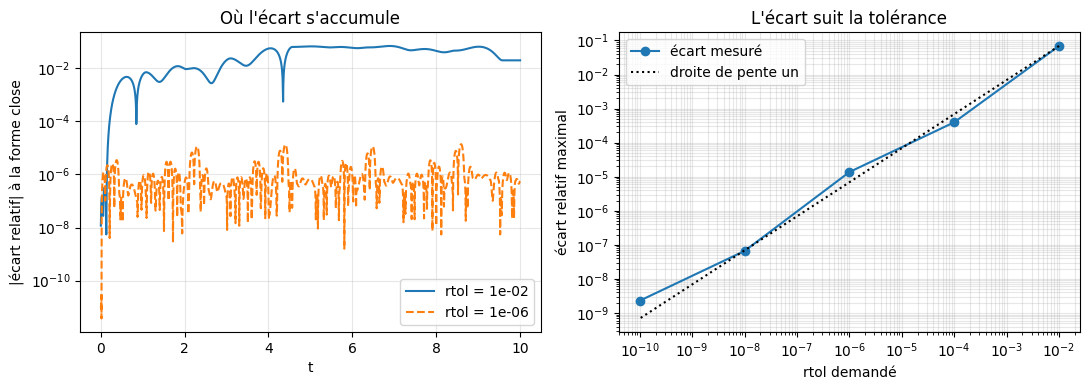

In [8]:
# Figure : ou l'ecart s'accumule, et comment il suit la tolerance.
instants = np.linspace(0.0, T_FIN, 2001)[1:]   # t = 0 ecarte : l'ecart y est nul
attendu = reference(instants, CAS_BASE)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Panneau gauche : ecarts relatifs le long de l'intervalle, pour deux tolerances.
for rtol, style in ((1e-2, "-"), (1e-6, "--")):
    integ = solve_ivp(second_membre(CAS_BASE), (0.0, T_FIN), [CAS_BASE["C0"]],
                      method="RK45", rtol=rtol, atol=ATOL, dense_output=True)
    ecart_local = np.abs(integ.sol(instants)[0] - attendu) / np.abs(attendu)
    axes[0].semilogy(instants, ecart_local, style, label=f"rtol = {rtol:.0e}")
axes[0].set_xlabel("t")
axes[0].set_ylabel("|écart relatif| à la forme close")
axes[0].set_title("Où l'écart s'accumule")
axes[0].legend()
axes[0].grid(True, which="both", alpha=0.3)

# Panneau droit : ecarts maximaux du balayage, contre la tolerance demandee.
axes[1].loglog([ligne[0] for ligne in resultats], [ligne[1] for ligne in resultats],
               "o-", label="écart mesuré")
# Droite de pente un, ancree sur le premier point : a quoi ressemblerait une
# proportionnalite exacte entre ecart et rtol.
guide = np.array([resultats[0][1] * (ligne[0] / resultats[0][0]) for ligne in resultats])
axes[1].loglog([ligne[0] for ligne in resultats], guide, "k:", label="droite de pente un")
axes[1].set_xlabel("rtol demandé")
axes[1].set_ylabel("écart relatif maximal")
axes[1].set_title("L'écart suit la tolérance")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()


**Lecture de la figure.** À gauche, l'écart relatif n'est ni uniforme ni monotone. Il atteint déjà quelques dixièmes de pour cent au bout d'un demi-intervalle, monte ensuite en oscillant, plafonne à quelques pour cent vers le milieu de l'intervalle, puis **retombe** au voisinage de `t = 10` : le dernier pas est raccourci pour atteindre exactement la borne, et l'erreur locale n'y a plus le temps de s'accumuler. Une oscillation se superpose à cette tendance, bien plus marquée à tolérance serrée qu'à tolérance lâche.

Les deux courbes ne se ressemblent pas point par point, mais elles se séparent de près de quatre ordres de grandeur — du même ordre que le rapport des deux tolérances. Le mécanisme ne change donc pas avec le réglage : seule l'échelle de l'erreur accumulée change.

À droite, les cinq points suivent la droite de pente un à un facteur deux ou trois près, sans régularité : selon la ligne, le point tombe au-dessous ou au-dessus. À la tolérance la plus serrée, l'écart mesuré vaut environ trois fois ce qu'annonce la droite. C'est cohérent avec une pente légèrement inférieure à un : un écart relatif **total** n'est pas exactement proportionnel à une tolérance **par pas**, parce que le nombre de pas sur lequel s'accumule l'erreur dépend lui-même de cette tolérance.


### 2.3 Un pas choisi par l'utilisateur : stabilité et précision

Le balayage précédent laisse un écart de quelques pour cent, pas une catastrophe : un solveur adaptatif masque en partie le problème, puisqu'il choisit ses pas. Le même problème confié à un schéma à **pas fixe** montre ce qui arrive quand le pas est choisi sans contrôle.

Le schéma d'Euler explicite avance par $y_{n+1} = y_n - h\,\kappa(t_n)\,y_n$. Pour l'équation modèle $y' = -\lambda y$, il multiplie par $1 - h\lambda$ à chaque pas : il ne peut rester borné que si $|1 - h\lambda| \le 1$, c'est-à-dire $h\lambda \le 2$. Au-delà, la suite numérique diverge — et elle change de signe à chaque pas, puisque $1 - h\lambda < -1$.

Deux réserves avant de lire le tableau. Ce seuil est un seuil de **stabilité**, pas de précision : un pas qui le respecte peut rester borné et rendre un résultat faux. Et il est établi sur un coefficient **constant** ; avec $\kappa$ variable, il ne vaut que localement, comme indication.

Pour rendre le franchissement visible sans dérouler des milliers de pas, on durcit le coefficient de perte : $k_0 = 200$ sur un intervalle court, $0 \le t \le 0{,}02$, qui couvre encore quatre décroissances.


In [9]:
# Cas raide : meme equation, coefficient de perte vingt fois plus grand,
# intervalle court (quatre decroissances).
CAS_RAIDE = {"k0": 200.0, "eps": 0.5, "omega": 3.0, "C0": 1.0}
T_RAIDE = 0.02


def euler_pas_fixe(cas, h, t_final):
    """Schema d'Euler explicite a pas fixe ; renvoie les instants et les valeurs."""
    n_pas = int(round(t_final / h))
    instants = np.arange(n_pas + 1) * h
    valeurs = np.empty(n_pas + 1)
    valeurs[0] = cas["C0"]
    for i in range(n_pas):
        pertes = cas["k0"] * (1.0 + cas["eps"] * np.cos(cas["omega"] * instants[i]))
        valeurs[i + 1] = valeurs[i] - h * pertes * valeurs[i]
    return instants, valeurs


# Le seuil porte sur le produit |kappa| h, dans sa version maximale.
kappa_max = CAS_RAIDE["k0"] * (1.0 + CAS_RAIDE["eps"])

print(f"{'h':>9} {'|kappa| h':>10} {'écart relatif max':>18} {'y final':>12} {'référence':>12}")
for h in (0.0005, 0.001, 0.0025, 0.005, 0.01, 0.02):
    instants, valeurs = euler_pas_fixe(CAS_RAIDE, h, T_RAIDE)
    attendu = reference(instants, CAS_RAIDE)
    ecart_max = np.max(np.abs(valeurs - attendu) / np.abs(attendu))
    print(f"{h:>9.4f} {kappa_max * h:>10.2f} {ecart_max:>18.3e} "
          f"{valeurs[-1]:>12.4e} {attendu[-1]:>12.4e}")

# Contraste : le meme intervalle, confie au solveur adaptatif.
print("\nMeme intervalle, solveur adaptatif RK45 :")
for rtol in (1e-2, 1e-6):
    ecart, evaluations = ecart_a_la_forme_close(CAS_RAIDE, rtol=rtol, atol=ATOL,
                                               t_final=T_RAIDE)
    print(f"  rtol = {rtol:.0e} : écart relatif max = {ecart:.3e} ; "
          f"évaluations = {evaluations}")


        h  |kappa| h  écart relatif max      y final    référence
   0.0005       0.15          3.938e-01   1.5043e-03   2.4817e-03
   0.0010       0.30          6.780e-01   7.9919e-04   2.4817e-03
   0.0025       0.75          9.938e-01   1.5319e-05   2.4817e-03
   0.0050       1.50          2.414e+01   6.2402e-02   2.4817e-03
   0.0100       3.00          1.610e+03   3.9991e+00   2.4817e-03
   0.0200       6.00          2.016e+03  -5.0000e+00   2.4817e-03

Meme intervalle, solveur adaptatif RK45 :
  rtol = 1e-02 : écart relatif max = 3.986e-02 ; évaluations = 32
  rtol = 1e-06 : écart relatif max = 1.595e-06 ; évaluations = 164


**Lecture du tableau.** Deux ruptures s'y lisent, et elles n'ont pas la même nature.

**La rupture de précision vient en premier, et de loin.** Dès le pas le plus petit, `h = 0,0005`, où le produit $|\kappa|h$ vaut $0{,}15$ et où le schéma est parfaitement stable, l'écart atteint déjà près de quarante pour cent. Euler est d'ordre un : diviser le pas par deux divise l'erreur par deux, ce qui reste très grossier pour une solution qui perd quatre décades en vingt millisecondes. Pour passer sous le pour cent sur ce cas, il faudrait descendre encore bien en dessous du plus petit pas du tableau.

**La rupture de stabilité vient ensuite, et elle est franche.** À `h = 0,005`, le produit vaut $1{,}50$ : le facteur $|1 - h\kappa|$ vaut encore $0{,}5$, le schéma reste borné, et l'écart est pourtant de l'ordre de vingt-quatre. C'est le cas qui ruine l'idée qu'un pas « stable » serait un pas « bon ». À `h = 0,01`, le produit franchit $2$ et l'écart saute à plus de mille six cents. À `h = 0,02`, un seul pas suffit : le facteur vaut $1 - 6 = -5$, et la concentration finale sort **négative** alors que toute solution de cette équation reste positive. Le critère $h\lambda \le 2$ annonce donc l'endroit où la divergence commence.

**Le contraste avec le solveur adaptatif** est la morale de la section. Sur le même intervalle, RK45 rend un écart de quatre pour cent à `rtol = 1e-2` pour trente-deux évaluations, et de l'ordre du millionième à `rtol = 1e-6` pour moins de deux cents. Il ne choisit pas un pas « sûr » : il choisit, à chaque pas, le plus grand pas qui tienne la précision demandée.


### Exercice 2 — Ce que `atol` protège, et ce qu'il fausse

Toutes les mesures de cette partie gardent `atol` à `1e-14`, très en dessous de la solution. C'est ce qui permet à `rtol` de gouverner seul l'écart. Si on laisse `atol` à une valeur ordinaire — `1e-2`, par exemple —, que devient la mesure ?

Le seuil effectif du solveur est `atol + rtol * |y|`. Quand la solution décroît, ce seuil cesse d'être proportionnel à elle : passé un certain temps, `|y|` devient plus petite que `atol`, et c'est alors `atol` qui fixe l'erreur **absolue** acceptée. Une solution de l'ordre de $10^{-4}$ approchée à $10^{-2}$ près n'est plus approchée du tout, et l'erreur **relative** explose — tandis que l'erreur absolue, elle, reste exactement sous le seuil demandé.

**À faire** : reprendre la mesure de la section 2.2 avec `rtol = 1e-8` et deux valeurs de `atol` — `1e-14`, puis `1e-2` — et conclure sur la grandeur que chaque tolérance protège.


In [10]:
# Exercice 2 — Ce que atol protege, et ce qu'il fausse
#
# Etape 1 : mesurer l'ecart relatif maximal de CAS_BASE avec rtol = 1e-8 et atol = 1e-14.
# Etape 2 : refaire la mesure avec rtol = 1e-8 et atol = 1e-2.
# Etape 3 : comparer les deux ecarts, puis reperer a partir de quel instant la
#           solution devient plus petite que atol.
#
# Indice : la valeur de la forme close a t = 10 est de l'ordre de 5e-05 ;
#          comparez-la a la valeur de atol utilisee.

def ecarts_selon_atol():
    """Renvoie (ecart avec atol = 1e-14, ecart avec atol = 1e-2). TODO étudiant."""
    result = None  # TODO étudiant
    return result


print("Exercice 2 à compléter : rôle de atol quand la solution devient petite.")


Exercice 2 à compléter : rôle de atol quand la solution devient petite.


### Exercice 3 — Le pas limite, et ce qu'il coûte

Deux quantités se lisent dans la section 2.3, et aucune n'est gratuite : le pas à partir duquel Euler cesse d'être utilisable sur un cas, et le nombre de pas qu'il faut payer pour une précision donnée.

**À faire** :

1. sur le cas de base (coefficient modulé, intervalle $0 \le t \le 10$), chercher par essais successifs le plus grand pas pour lequel l'écart relatif maximal d'Euler reste sous le pour cent ;
2. compter les pas correspondants ;
3. comparer ce nombre aux évaluations que RK45 demande pour un écart comparable (section 2.2), et conclure sur ce qu'un schéma d'ordre un paie pour approcher la précision d'un schéma d'ordre cinq.

**Le piège à éviter** : conclure du seuil de stabilité. Sur le cas de base, $|\kappa| \le 1{,}5$, donc un pas de $1$ serait stable au sens de $h\lambda \le 2$ — et donnerait un résultat sans valeur. Ce qui fixe le pas utile ici est la précision, pas la stabilité.


In [11]:
# Exercice 3 — Le pas limite, et ce qu'il coute
#
# Etape 1 : chercher le plus grand h tel que l'ecart relatif maximal d'Euler
#           sur CAS_BASE reste sous 1e-2 (essais successifs, du plus grand au plus petit).
# Etape 2 : compter les pas utilises, T_FIN / h.
# Etape 3 : comparer ce nombre aux evaluations de RK45 pour un ecart comparable
#           (section 2.2), et conclure sur l'ordre du schema.
#
# Indice : commencer par h = 0.5, puis diviser le pas par deux tant que l'ecart
#          depasse le seuil ; euler_pas_fixe accepte n'importe quel cas et intervalle.

def pas_limite_euler():
    """Plus grand h d'Euler dont l'ecart relatif maximal reste sous 1e-2. TODO étudiant."""
    result = None  # TODO étudiant
    return result


print("Exercice 3 à compléter : pas limite d'Euler pour un écart de un pour cent.")


Exercice 3 à compléter : pas limite d'Euler pour un écart de un pour cent.


## Partie 3 — Ce qu'une preuve formelle établit, et ce qu'elle n'établit pas

### 3.1 Un théorème du dépôt, sur la même classe d'équations

Le dépôt contient des preuves formelles en Lean 4, hors de cette série. L'une d'elles porte sur la classe d'équations de ce carnet : elle se trouve dans le fichier `ML/learning_theory_lean/EffectiveTheory/GrokkingLemmas.lean`, et deux énoncés s'y composent.

Le premier est un lemme de calcul différentiel, `eq_of_hasDerivAt_zero` : une fonction réelle dont la dérivée est nulle en tout point est constante. Sa démonstration tient en une ligne, appuyée sur `is_const_of_deriv_eq_zero` de Mathlib.

Le second, `meanZero_invariant`, est celui qui nous intéresse. Il considère une courbe $\gamma$ qui suit le flot effectif d'un problème d'apprentissage, et la quantité $C(t) = \sum_k \gamma_k(t)$. Le long de cette courbe, la dérivée de $C$ est proportionnelle à $C$ :

$$C'(t) = \kappa(t)\,C(t), \qquad \kappa(t) = \frac{2\,\ell_0(\gamma(t))}{Z_0(\gamma(t))^2},$$

où $\ell_0$ et $Z_0$ sont les fonctions `loss0` et `sumsq0` du fichier. Cette relation est établie par un théorème voisin, `flow_deriv_sum_apply`, dans le fichier `Grokking.lean`.

La continuité de $\kappa$ est une **hypothèse explicite** du théorème (`hκcont`), aux côtés de trois autres : $\gamma$ suit ce flot (`hγ`), $Z_0(\gamma(t))$ ne s'annule pas (`hZ0`), et $C(0) = 0$ (`h0`). La conclusion porte sur tout temps réel : $C(t) = 0$.

La démonstration fait ce que ferait le calcul à la main. Elle pose $K(t) = \int_0^t \kappa$, puis $F(t) = C(t)\,e^{-K(t)}$ — le facteur intégrant. Elle établit que $F'$ est nulle en tout point, puisque $C'e^{-K}$ et $C\kappa e^{-K}$ s'annulent mutuellement ; elle en déduit que $F$ est constante, par le premier lemme ; elle constate que $F(0) = C(0) = 0$ ; elle conclut que $C(t)\,e^{-K(t)} = 0$, donc $C(t) = 0$, l'exponentielle ne s'annulant jamais.

Notre équation appartient à la même classe, à deux différences près : le coefficient est $-\kappa$ au lieu de $\kappa$, et sa valeur est la modulation $k_0\,(1 + \varepsilon\cos\omega t)$ au lieu d'un rapport de deux quantités du flot. Le changement de signe renverse le sens de variation de $C$ ; la structure de l'équation, elle, est identique. **Le théorème n'est donc pas énoncé pour notre équation** : il l'est pour un cas particulier de sa classe, avec un argument qui s'appliquerait au nôtre. Ce carnet le lit, il ne l'étend pas.


### 3.2 Une conséquence du théorème, confiée au solveur

Le théorème de la section 3.1 porte une conséquence qualitative : une solution partie de zéro y reste. Cette conséquence se soumet au solveur de la partie 2, qui ne prouve rien mais peut contredire. L'expérience comporte un contre-témoin — une condition initiale minuscule, mais non nulle, qui doit donner une solution non nulle : sans lui, un solveur qui rendrait zéro par défaut passerait pour conforme.


In [12]:
# Consequence qualitative : parti de C(0) = 0, la solution numerique reste-t-elle nulle ?
CAS_NUL = dict(CAS_BASE, C0=0.0)
for rtol in (1e-2, 1e-6, 1e-10):
    integ = solve_ivp(second_membre(CAS_NUL), (0.0, T_FIN), [CAS_NUL["C0"]],
                      method="RK45", rtol=rtol, atol=ATOL)
    print(f"rtol = {rtol:.0e} : max|y| = {np.max(np.abs(integ.y[0])):.3e}"
          f" ; évaluations = {integ.nfev}")

# Contre-temoin : condition initiale minuscule, mais non nulle.
CAS_PETIT = dict(CAS_BASE, C0=1e-3)
integ = solve_ivp(second_membre(CAS_PETIT), (0.0, T_FIN), [CAS_PETIT["C0"]],
                  method="RK45", rtol=1e-6, atol=ATOL)
print(f"C(0) = 1e-3 : max|y| = {np.max(np.abs(integ.y[0])):.3e}")


rtol = 1e-02 : max|y| = 0.000e+00 ; évaluations = 50
rtol = 1e-06 : max|y| = 0.000e+00 ; évaluations = 50
rtol = 1e-10 : max|y| = 0.000e+00 ; évaluations = 50
C(0) = 1e-3 : max|y| = 1.000e-03


**Lecture du résultat.** Les trois premières lignes rendent zéro, exactement, aux trois tolérances — et pour un coût identique : cinquante évaluations à chaque fois. Ce n'est pas une performance du solveur : parti de zéro sur un second membre linéaire, il reste à zéro à chaque étape, quel que soit son pas. Le coût ne varie pas, faute d'erreur à contrôler.

La dernière ligne est le contre-témoin : une condition initiale de $10^{-3}$ — minuscule, mais non nulle — donne une solution non nulle, dont le maximum est la condition initiale elle-même, puisque la solution décroît. La mesure distingue donc bien les deux situations.

Le théorème et la mesure disent la même chose, mais pas avec la même portée : le théorème l'affirme pour tout temps, sur le coefficient issu du flot, et sa démonstration n'utilise de ce coefficient que sa continuité — une hypothèse explicite ; la mesure, elle, l'a constaté sur un intervalle et trois réglages. Et un solveur qui rendrait un résultat non nul en partant de $C_0 = 0$ serait un solveur défectueux, pas une exception au théorème.


### 3.3 Qui établit quoi — table des affirmations

| Affirmation | Qui l'établit | Ce qui reste hors de portée |
|---|---|---|
| La forme close satisfait l'équation et la condition initiale | SymPy : deux résidus exactement nuls (section 1.3) | Rien, sur ces deux points : c'est un calcul exact |
| La solution issue de $C_0 = 0$ reste nulle | Lean : `meanZero_invariant` (section 3.1) | L'énoncé y est prouvé pour le coefficient issu du flot ; « pour tout $\kappa$ continu » n'y est pas un lemme nommé |
| La solution est unique pour $C_0 \neq 0$ | Rien dans ce carnet | Une preuve d'unicité n'est ni citée ni reproduite |
| RK45 atteint l'écart mesuré | Mesure : cinq tolérances, un cas (section 2.2) | Ce n'est pas une borne *a priori* : l'écart dépend du problème et de l'intervalle |
| Euler diverge au-delà de $h\kappa = 2$ | Mesure et argument sur le facteur $1 - h\lambda$ (section 2.3) | L'argument vaut pour un coefficient constant ; avec $\kappa$ variable, il n'est qu'une indication |
| Le coût croît quand la tolérance se resserre | Mesure : section 2.2 | Ce n'est pas une loi : un autre schéma paie autrement |


### 3.4 Ce que ce carnet ne prouve pas

Les écarts de la partie 2 sont des mesures sur un cas, un intervalle et quelques réglages. Ils ne constituent pas une borne d'erreur : rien ici ne dit que RK45 restera sous le même écart sur un autre problème, ni que le seuil $h\kappa = 2$ gouverne un coefficient variable autrement que localement. La preuve Lean, de son côté, ne parle pas du code : aucun énoncé du fichier cité ne relie ses théorèmes à `solve_ivp`, et rien dans ce carnet ne vérifie que le solveur applique le schéma qu'il annonce.

Trois affirmations restent donc hors du carnet. Elles sont nommées ici pour être opposables, et non passées sous silence :

1. **l'unicité** de la solution pour $C_0 \neq 0$ ;
2. une **borne d'erreur *a priori*** pour le solveur adaptatif ;
3. un **lien formel** entre le théorème de la section 3.1 et le code de la partie 2.

La table de la section 3.3 se lit dans ce sens : chaque ligne dit qui porte l'affirmation, et ce que ce porteur ne couvre pas. Une lecture qui sauterait la dernière colonne croirait avoir tout vérifié.

Jamais ce carnet n'écrit « vérifié de bout en bout ».


## Vérifiez votre compréhension

1. **Le résidu nul de la section 1.3 prouve-t-il que la forme close est l'unique solution de l'équation ?**

<details>
<summary>Éléments de réponse</summary>

Non. Il prouve que le candidat **est** une solution : il satisfait l'équation et la condition initiale. Il ne dit rien d'une autre solution qui existerait à côté. L'unicité est un énoncé distinct, et il n'est pas établi dans ce carnet.

</details>

2. **Pourquoi l'écart mesuré dépasse-t-il la tolérance demandée ?**

<details>
<summary>Éléments de réponse</summary>

Parce que `rtol` porte sur l'erreur **locale**, à chaque pas, alors que la mesure porte sur l'écart **total** après l'intervalle entier. Les erreurs locales s'accumulent : la pente proche de un dit que l'écart total reste proportionnel à la tolérance, avec un facteur d'amplification supérieur à un.

</details>

3. **Un schéma stable peut-il rendre un résultat faux ? Où le voit-on dans ce carnet ?**

<details>
<summary>Éléments de réponse</summary>

Oui. Dans la section 2.3, à `h = 0,005`, le facteur $|1 - h\kappa|$ vaut $0{,}5$ : le schéma reste borné, et l'écart atteint environ vingt-quatre. La stabilité garantit seulement que la suite ne diverge pas ; elle ne dit rien de sa distance à la solution.

</details>

4. **Que rend le solveur quand il part de $C_0 = 0$, et pourquoi est-ce un témoin plutôt qu'une preuve ?**

<details>
<summary>Éléments de réponse</summary>

Il rend zéro, aux trois tolérances testées, parce que le second membre est linéaire et envoie zéro sur zéro. Cette mesure ne pourrait échouer que si le solveur était défectueux ; elle ne dit rien de l'équation. Le théorème cité en partie 3 établit la même conclusion pour tout temps, sans exécuter de calcul — pour le coefficient issu du flot, dont la continuité est une hypothèse.

</details>

5. **Le théorème `meanZero_invariant` est-il énoncé pour l'équation de ce carnet ?**

<details>
<summary>Éléments de réponse</summary>

Pas littéralement. Il est énoncé pour une courbe qui suit un flot particulier, avec un coefficient $\kappa$ dont la continuité est une hypothèse. Notre équation a la même structure, avec un autre coefficient et un signe opposé. L'argument de la démonstration — facteur intégrant, dérivée nulle — s'appliquerait à la nôtre, mais l'énoncé général n'est pas un lemme nommé du dépôt.

</details>


## À retenir

| Notion | Ce qu'elle dit | Où la voir |
|---|---|---|
| Résidu de substitution | Remplacer un candidat dans l'équation et dans la condition initiale : deux zéros exacts valent vérification, un non-nul vaut réfutation | Section 1.3 |
| Témoin négatif | Un contrôle qui n'a jamais rejeté un candidat faux ne prouve rien : on lui en soumet un exprès | Section 1.3 |
| Tolérance par pas | `rtol` borne l'erreur **locale** ; l'écart total en hérite, multiplié par un facteur d'accumulation | Section 2.2 |
| `atol` | Tolérance **absolue** : elle gouverne là où la solution devient plus petite qu'elle | Exercice 2 |
| Stabilité | $|1 - h\lambda| \le 1$ : la suite ne diverge pas — et c'est tout | Section 2.3 |
| Précision | La distance à la solution : elle se mesure, elle ne se déduit pas de la stabilité | Section 2.3 |
| Facteur intégrant | $C\,e^{-\int\kappa}$ a une dérivée nulle quand $C' = \kappa C$ ; une fonction de dérivée nulle est constante | Section 3.1 |
| Portée d'une preuve | Ce qu'un théorème certifie vaut au-delà de toute tolérance — sur ses hypothèses seulement, jamais sur le code | Sections 3.3 et 3.4 |


## Pour aller plus loin

- **Prolongement direct** : une fois l'exercice 3 franchi, remplacer Euler par un schéma d'ordre deux (Heun) et mesurer, sur le cas raide de la section 2.3, ce que l'ordre ajoute — et s'il change le seuil de stabilité.
- **Grains ouverts côté formel** : extraire de la démonstration de `meanZero_invariant` l'énoncé général « pour tout $\kappa$ continu, la solution de $C' = \kappa C$ issue de zéro reste nulle » ; puis décider d'un pont preuve/code, qui n'existe pas aujourd'hui. Ce carnet mesure, il ne démontre pas.
- **Carnets voisins — discrétisation** : [Numérique-01 — Burgers par volumes finis](../Physique/Numerique/Numerique-01-Burgers-Volumes-Finis-Python.ipynb) mesure un ordre de convergence sur une équation aux dérivées partielles ; la sous-série [Physique/Numerique](../Physique/Numerique/README.md) en donne le fil.
- **Carnets voisins — preuves** : le fichier cité en partie 3 appartient à la série [ML/learning_theory_lean](../ML/learning_theory_lean/README.md) ; la sous-série [SymbolicAI/Lean](../SymbolicAI/Lean/README.md) apprend à lire et à écrire des démonstrations.


## Références et provenance

### Provenance pédagogique

Ce carnet est le pilote d'une série additive, « Calcul scientifique — forme close, mesure, preuve », qui met côte à côte trois voies sur un même problème : le calcul exact, la mesure numérique et l'énoncé formel. Il n'emprunte aucun contenu à une série existante ; il renvoie aux séries voisines pour la discrétisation et pour les preuves.

### Ce qui est mesuré, cité, établi

- **Mesuré dans ce carnet** : les résidus de la section 1.3, les écarts des sections 2.2 et 2.3, le coût en évaluations, les valeurs de la section 3.2. Toutes ces sorties proviennent de l'exécution du carnet, sans germe aléatoire : deux exécutions rejouent les mêmes nombres.
- **Lu, non exécuté** : les énoncés Lean de la section 3.1 sont cités depuis le fichier source du dépôt. Ce carnet ne les compile pas et ne les vérifie pas : il rapporte ce que le fichier déclare.
- **Établi ailleurs** : la démonstration de `meanZero_invariant` appartient à son fichier ; sa compilation relève de la chaîne Lean du dépôt, pas de ce carnet.

### Références

- Documentation SymPy : `sympy.dsolve` (résolution d'équations différentielles), `sympy.simplify` (forme canonique des résidus), `sympy.lambdify` (passage au calcul numérique).
- Documentation SciPy : `scipy.integrate.solve_ivp` (méthode `RK45`, paramètres `rtol` et `atol`, sortie dense).
- Fichier Lean cité : `ML/learning_theory_lean/EffectiveTheory/GrokkingLemmas.lean` — théorèmes `eq_of_hasDerivAt_zero` et `meanZero_invariant`. Le coefficient $\kappa$ y est calculé par `flow_deriv_sum_apply`, dans le fichier voisin `Grokking.lean`.
